In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('/content/netflix_titles.csv', encoding='latin1')

In [4]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,...,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8809 entries, 0 to 8808
Data columns (total 26 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   show_id       8809 non-null   object 
 1   type          8809 non-null   object 
 2   title         8809 non-null   object 
 3   director      6175 non-null   object 
 4   cast          7984 non-null   object 
 5   country       7978 non-null   object 
 6   date_added    8799 non-null   object 
 7   release_year  8809 non-null   int64  
 8   rating        8805 non-null   object 
 9   duration      8806 non-null   object 
 10  listed_in     8809 non-null   object 
 11  description   8809 non-null   object 
 12  Unnamed: 12   0 non-null      float64
 13  Unnamed: 13   0 non-null      float64
 14  Unnamed: 14   0 non-null      float64
 15  Unnamed: 15   0 non-null      float64
 16  Unnamed: 16   0 non-null      float64
 17  Unnamed: 17   0 non-null      float64
 18  Unnamed: 18   0 non-null    

In [6]:
print("Jumlah Baris dan Kolom:")
print(df.shape)

Jumlah Baris dan Kolom:
(8809, 26)


In [7]:
# Menghitung jumlah Movie dan TV Show
print(df['type'].value_counts())

type
Movie      6132
TV Show    2677
Name: count, dtype: int64


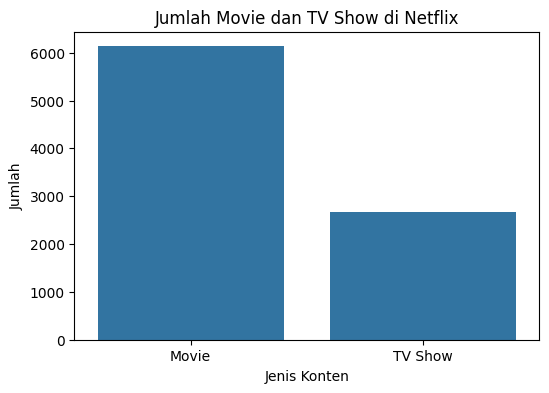

In [8]:
# Visualisasi
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x='type'
)

plt.title('Jumlah Movie dan TV Show di Netflix')
plt.xlabel('Jenis Konten')
plt.ylabel('Jumlah')

plt.show()

In [9]:
# Mengecek missing value
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [12]:
df.drop(columns=['Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25'], inplace=True)

In [13]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [14]:
print("Jumlah data duplikat :", df.duplicated().sum())

Jumlah data duplikat : 0


In [15]:
df = df.drop_duplicates()

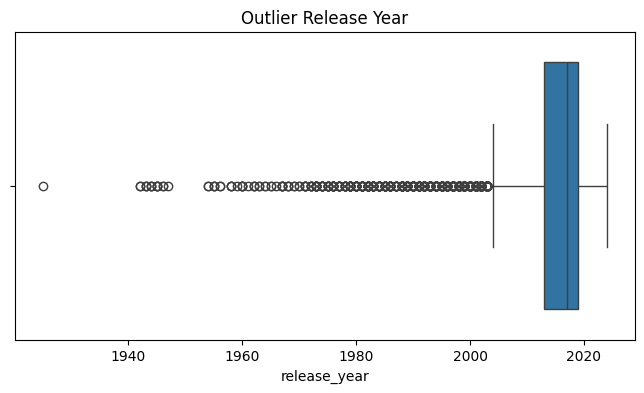

In [16]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df['release_year'])

plt.title("Outlier Release Year")
plt.show()

In [17]:
movies = df[df['type']=="Movie"].copy()

movies['duration_num'] = movies['duration'].str.replace(' min','')
movies['duration_num'] = pd.to_numeric(movies['duration_num'])

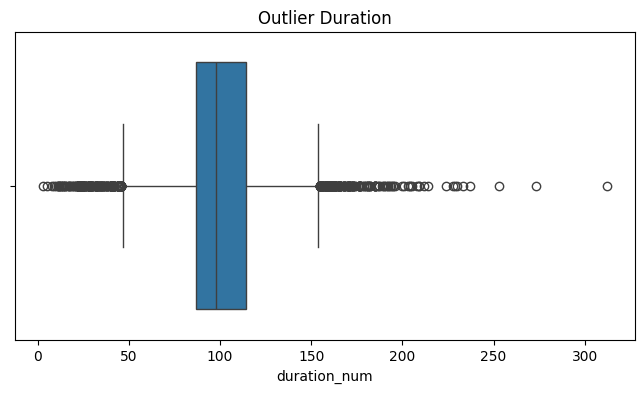

In [18]:
plt.figure(figsize=(8,4))

sns.boxplot(x=movies['duration_num'])

plt.title("Outlier Duration")
plt.show()

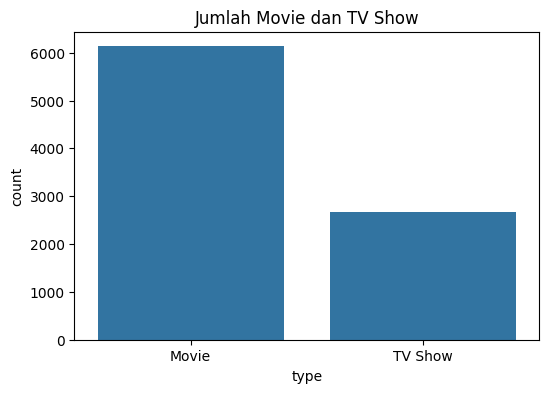

In [19]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x='type'
)

plt.title('Jumlah Movie dan TV Show')
plt.show()

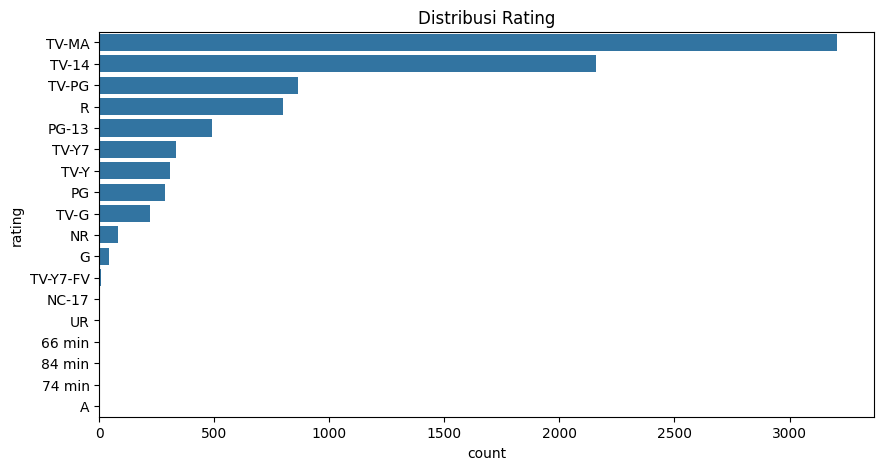

In [20]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    y='rating',
    order=df['rating'].value_counts().index
)

plt.title('Distribusi Rating')
plt.show()

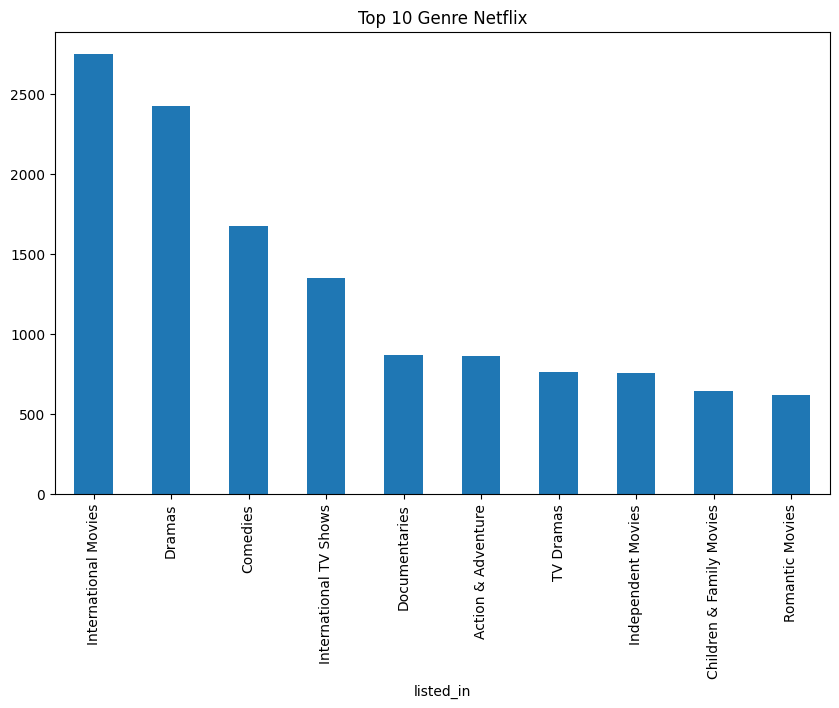

In [21]:
genre = df['listed_in'].str.split(', ').explode()

plt.figure(figsize=(10,6))

genre.value_counts().head(10).plot(kind='bar')

plt.title('Top 10 Genre Netflix')
plt.show()

In [22]:
movies = df[df['type']=='Movie'].copy()

movies['duration_num'] = movies['duration'].str.replace(' min','')

movies['duration_num'] = pd.to_numeric(
    movies['duration_num']
)

In [23]:
corr = movies[
    ['release_year','duration_num']
].corr()

corr

,release_year,duration_num
release_year,1.000000,-0.206277
duration_num,-0.206277,1.000000


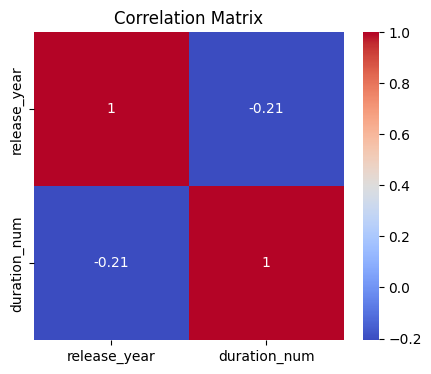

In [24]:
plt.figure(figsize=(5,4))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Matrix')
plt.show()

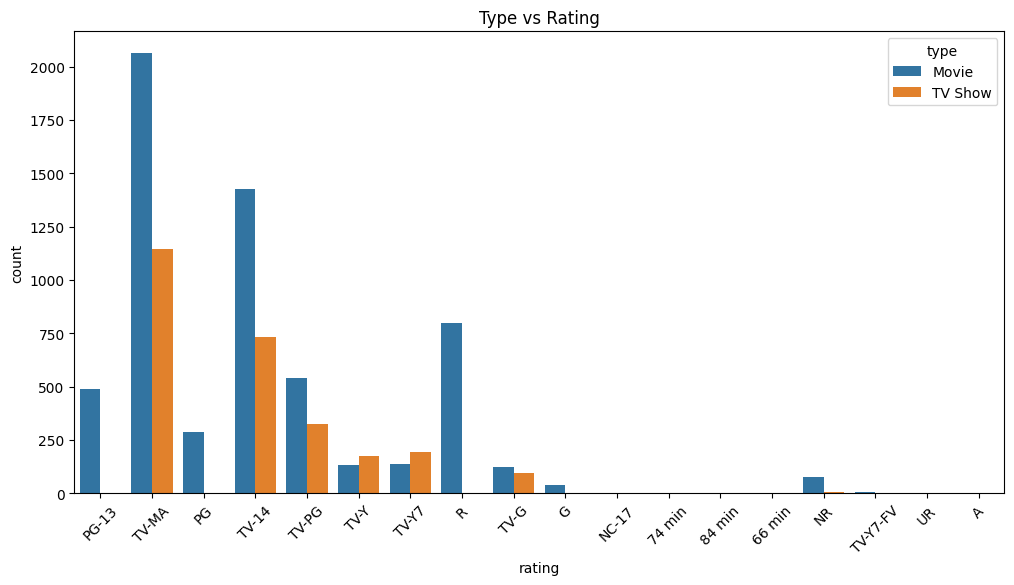

In [25]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    x='rating',
    hue='type'
)

plt.xticks(rotation=45)
plt.title('Type vs Rating')
plt.show()

In [26]:
country_genre = df[['country','listed_in']]

country_genre.head()

,country,listed_in
0,United States,Documentaries
1,South Africa,"International TV Shows, TV Dramas, TV Mysteries"
2,NaN,"Crime TV Shows, International TV Shows, TV Act..."
3,NaN,"Docuseries, Reality TV"
4,India,"International TV Shows, Romantic TV Shows, TV ..."


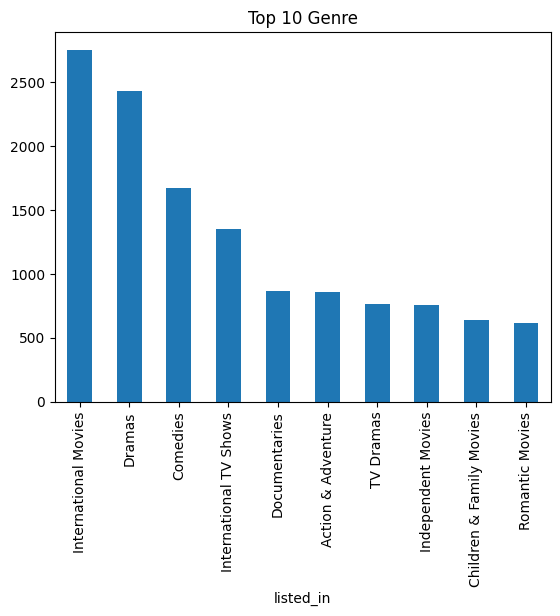

In [27]:
genre = df['listed_in'].str.split(', ').explode()

genre.value_counts().head(10).plot(kind='bar')

plt.title('Top 10 Genre')
plt.show()

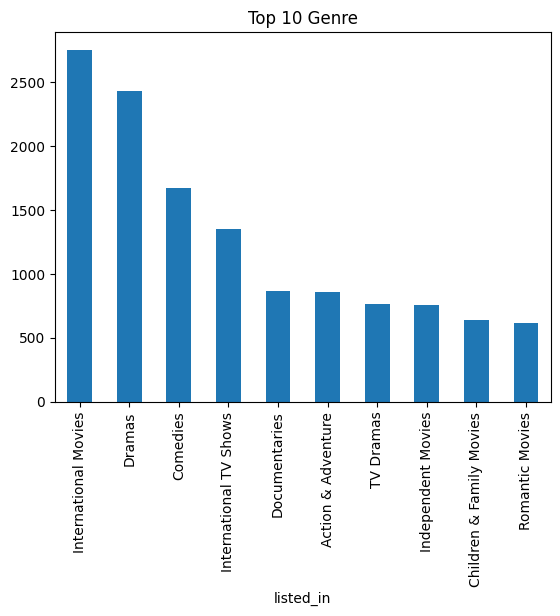

In [28]:
genre = df['listed_in'].str.split(', ').explode()

genre.value_counts().head(10).plot(kind='bar')

plt.title('Top 10 Genre')
plt.show()

In [30]:
df['date_added'] = pd.to_datetime(
    df['date_added'],
    errors='coerce'
)

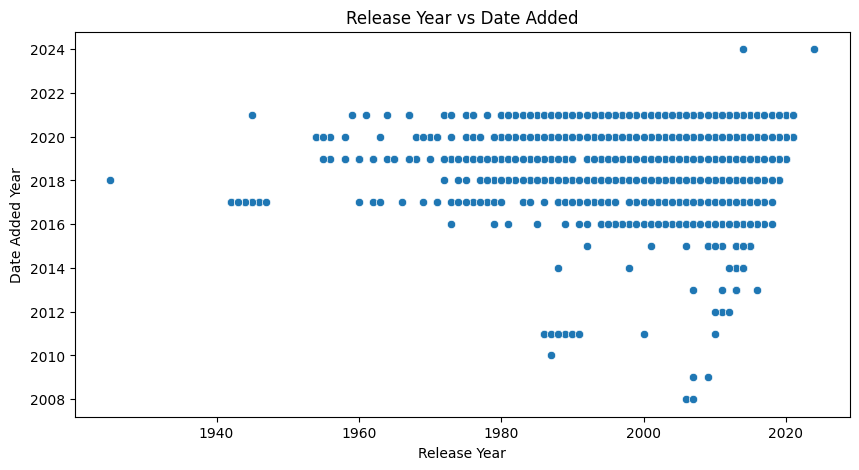

In [31]:
plt.figure(figsize=(10,5))

sns.scatterplot(
    data=df,
    x='release_year',
    y=df['date_added'].dt.year
)

plt.title('Release Year vs Date Added')
plt.xlabel('Release Year')
plt.ylabel('Date Added Year')

plt.show()

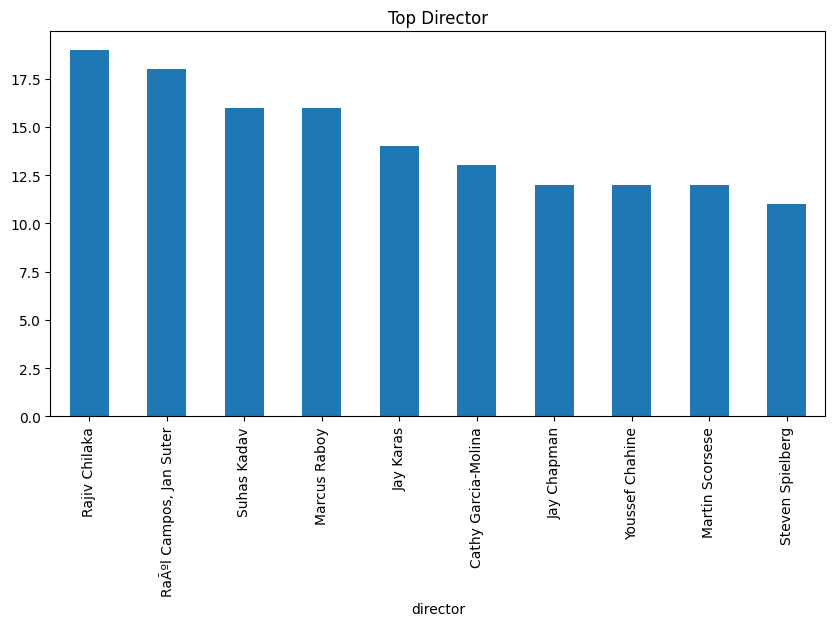

In [33]:
plt.figure(figsize=(10,5))

df['director'].value_counts().head(10).plot(kind='bar')

plt.title('Top Director')
plt.show()

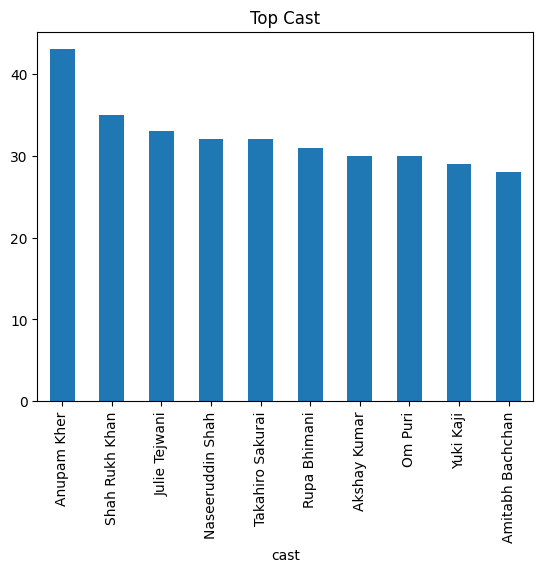

In [34]:
cast = df['cast'].str.split(', ').explode()

cast.value_counts().head(10).plot(kind='bar')

plt.title('Top Cast')
plt.show()

In [35]:
movies = df[df['type']=='Movie'].copy()

movies['duration_num'] = (
    movies['duration']
    .str.replace(' min','')
    .astype(float)
)

corr = movies[
    ['release_year','duration_num']
].corr()

print(corr)

              release_year  duration_num
release_year      1.000000     -0.206277
duration_num     -0.206277      1.000000


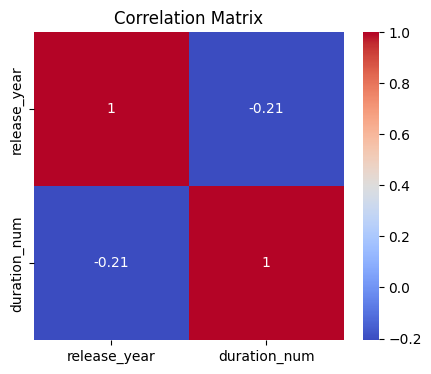

In [36]:
plt.figure(figsize=(5,4))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Matrix')
plt.show()